# 04 · Final research report and optimal execution

Real-data findings with explicit market/account scope and uncalibrated assumptions. The optimal-execution mandate starts with settled inventory and is separate from the empty-account signal strategy.

In [1]:
import json

import pandas as pd
from IPython.display import Image, Markdown, display

from market_microstructure.utils.config import load_config
from market_microstructure.utils.paths import PROJECT_ROOT

ROOT = PROJECT_ROOT
config = load_config()
def table(name):
    return pd.read_csv(ROOT / 'outputs' / 'tables' / f'{name}.csv')
def figure(name):
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / f'{name}.png')))
features = pd.read_parquet(ROOT / config['data']['features_path'])
assert set(features.asset) == {'000400.SZ'}
assert features.timestamp.dt.tz is not None


In [2]:
report = (ROOT / 'outputs/research_report.md').read_text(encoding='utf-8')
display(Markdown(report.split('## Figures')[0]))

# Market Microstructure & Execution — real A-share research report

## Scope and provenance

Primary data: **000400.SZ (Xu Ji Electric), 2022-06-01**, 14,179 reconstructed five-level snapshots. The adapter replayed 222,651 messages from a pinned public sample. 41 crossed states were counted and excluded; no missing-order reference or over-reduction was recorded. There is no official exchange snapshot for independent verification. These are reconstructed public historical observations, not certified vendor L2 snapshots.

[Pinned raw-data source](https://github.com/Agnes252/LOB-Reconstruction/tree/12c60567d4a20aece2dd6e27f63e30339ec233e7/data_test). See tables/public_sample_manifest.json for SHA-256, tables/reconstruction_audit.json for replay accounting, and tables/ashare_source_probe.json for live-provider failures/staleness. AKShare and Easyquotation Python adapters were probed; live holiday quotes were not substituted into historical research.

OOS interval: 2022-06-01T10:20:08+08:00 through 2022-06-01T14:45:38+08:00. Complete chronological test windows are retained; this endpoint is the last OOS quote, not an official closing auction. Labels and rolling features reset at lunch/session boundaries.

## Main findings

The selected logistic signal has within-day OOS IC **0.303**, with timestamp-block bootstrap interval [0.241, 0.359]. This interval measures conditional uncertainty within one day; it does not establish cross-day or cross-stock stability.

Selected taker net **marked** PnL is **CNY 803.41**, with 10 fills and 940 shares left. **No lots close** under same-day T+1; positive PnL is held-stock appreciation, not realized intraday round-trip profit. The identical-rules constant-long benchmark marks **CNY 857.29**. Thus prediction and gross return must be assessed against directional exposure, fees and delayed liquidation.

The taker and benchmark hold different final share quantities and invested notionals because of capacity and lot constraints. Raw PnL differences are not exposure-normalized excess returns and cannot independently establish signal underperformance or alpha.

## Statistical evaluation

| model | rows | labeled_rows | signal_ic | accuracy | balanced_accuracy | precision | recall | roc_auc | r2 | mse_bps2 | mae_bps | pearson | spearman |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| forest | 10500 | 10490 | 0.2596 | 0.5194 | 0.4920 | 0.5426 | 0.4920 | 0.6870 | unavailable | unavailable | unavailable | unavailable | unavailable |
| linear | 10500 | 10490 | 0.2547 | unavailable | unavailable | unavailable | unavailable | unavailable | 0.0657 | 113.6159 | 6.9689 | 0.2620 | 0.3202 |
| logistic | 10500 | 10490 | 0.3028 | 0.5266 | 0.5151 | 0.5208 | 0.5151 | 0.6999 | unavailable | unavailable | unavailable | unavailable | unavailable |

Linear metrics are in bps; classification is {-1, 0, +1} with a 0.5 bps neutral band. AUC is macro one-vs-rest. Balanced accuracy/macro precision and recall complement accuracy. All preprocessing fits training data only. Expanding folds purge immature labels and embargo the boundaries. Validation permutation importance never uses test labels. Overlapping labels remain dependent despite purging.

## Fixed feature ablations

| feature_set | feature_count | signal_ic | accuracy | balanced_accuracy | precision | recall | roc_auc |
| --- | --- | --- | --- | --- | --- | --- | --- |
| imbalance_only | 1 | 0.1594 | 0.4585 | 0.4149 | 0.3045 | 0.4149 | 0.5692 |
| imbalance_spread_depth | 3 | 0.1947 | 0.4453 | 0.4141 | 0.4072 | 0.4141 | 0.6148 |
| full_features | 13 | 0.3028 | 0.5266 | 0.5151 | 0.5208 | 0.5151 | 0.6999 |

These feature sets were fixed before the report and share fold boundaries, regularization and label rules. They assess incremental predictive content on this day; they are not a feature search or an independent discovery sample. Top mean validation permutation features: imbalance_1, microprice_deviation_bps, signed_volume_imbalance. OLS HAC t statistics and coefficient drift are in feature_importance.csv. Highly related imbalance, spread and microprice variables make joint coefficients unstable; importance does not establish causality.

## Prediction versus execution

| model | mode | gross_pnl | net_pnl | total_fees | trade_count | residual_inventory_abs | closed_lot_count |
| --- | --- | --- | --- | --- | --- | --- | --- |
| forest | mid | 1061.5000 | 1061.5000 | 0.0000 | 10 | 1000.0000 | 0 |
| forest | taker | 978.2500 | 889.6284 | 75.1860 | 15 | 950.0000 | 0 |
| forest | maker | 1154.0000 | 1104.8056 | 50.1944 | 10 | 1000.0000 | 0 |
| linear | mid | 929.0000 | 929.0000 | 0.0000 | 10 | 1000.0000 | 0 |
| linear | taker | 918.1500 | 842.2845 | 65.1948 | 13 | 990.0000 | 0 |
| linear | maker | 904.9000 | 850.4196 | 55.1804 | 11 | 920.0000 | 0 |
| logistic | mid | 916.5000 | 916.5000 | 0.0000 | 10 | 1000.0000 | 0 |
| logistic | taker | 861.0000 | 803.4066 | 50.1851 | 10 | 940.0000 | 0 |
| logistic | maker | 960.5000 | 910.8037 | 50.1963 | 10 | 1000.0000 | 0 |
| always_long | taker | 915.0000 | 857.2928 | 50.1969 | 10 | 1000.0000 | 0 |

Mid-price execution is labeled **UNREALISTIC UPPER BOUND** and charges no costs. Different fill paths and capacities mean it is not a mathematical upper bound on every maker result. Takers buy at ask and sell at bid with capacity, adverse slippage and temporary impact. Maker results use fixed-price resting limits, future-observation eligibility, approximate queue pressure and seeded probabilistic fills. Their apparent ranking is sensitive to the uncalibrated probability model and different inventory exposure; it is not exchange-matching evidence.

## PnL accounting and A-share constraints

Net marked PnL = realized gross alpha + gross inventory mark-to-market − spread cost − fees − slippage − impact. The event ledger reconciles this bridge against cash + marked inventory − initial capital at every timestamp. Cash-stock mode enforces no naked shorts, positive cash, 100-share buy submissions and T+1 settled-stock sales. Partial fills are integer shares. Commission: configured 3 bps with CNY 5 minimum per submitted order, charged incrementally across partial maker fills. Historical sell stamp tax is 10 bps and transfer fee is 0.1 bps; the separate live config uses 5 bps stamp tax after the 2023 cut. Broker commission is an assumption, not a universal tariff. Same-day sell taxes remain uncharged where T+1 blocks every sale. Closed-trade hit rate and completed holding periods are unavailable here. Sharpe is fixed-clock, unannualized, and has little inferential value for one day.

[Official stamp-tax reduction](https://fgk.chinatax.gov.cn/zcfgk/c102416/c5211343/content.html). [SZSE rules applicable to the 2022 sample](https://docs.static.szse.cn/www/lawrules/rule/trade/W020210331716400647184.pdf). Fee dates and account scope are explicit in configs/base.yaml.

## Maker markouts, decay and regimes

Mean signed 10-observation maker markout: **-1.008 bps**, from 10 simplified-model fills. Negative signed markout denotes adverse selection; spread capture and markout are recorded separately from total marked PnL. Future prices are used only for diagnostics.

| asset | peak_horizon_events | peak_ic | half_life_events | censored |
| --- | --- | --- | --- | --- |
| 000400.SZ | 10 | 0.3028 | 50 | False |

Half-life is the first sampled horizon after peak |IC| reaching half of that peak, rather than an exponential fitted parameter. Retained observations are approximately one second, with gaps where invalid books are excluded. Training-only median cutoffs define six marginal regimes. Each low/high pair partitions events; regimes across dimensions overlap, so their PnL must not be summed together. Maker fill rate is attributed to order-arrival cohorts, even if fills occur later in another regime.

| regime | rows | signal_ic | prediction_accuracy | net_pnl | spread_cost |
| --- | --- | --- | --- | --- | --- |
| low_volatility | 6426 | 0.3212 | 0.5220 | -456.1934 | 6.9000 |
| high_volatility | 4064 | 0.2927 | 0.5347 | 1236.1000 | 0.0000 |
| tight_spread | 7401 | 0.3124 | 0.5256 | -706.4169 | 2.5000 |
| wide_spread | 3099 | 0.2777 | 0.5289 | 1509.8235 | 4.4000 |
| low_liquidity | 1499 | 0.1418 | 0.4916 | -864.8000 | 0.0000 |
| high_liquidity | 9001 | 0.3360 | 0.5324 | 1668.2066 | 6.9000 |

## Conditional execution stresses

| scenario | parameter | net_pnl | trade_count | residual_inventory_abs | max_drawdown |
| --- | --- | --- | --- | --- | --- |
| baseline | 1.0000 | 803.4066 | 10 | 940.0000 | 728.5000 |
| latency_0 | 0.0000 | 857.2364 | 10 | 1000.0000 | 775.0000 |
| latency_1 | 1.0000 | 803.4066 | 10 | 940.0000 | 728.5000 |
| latency_5 | 5.0000 | 848.6605 | 11 | 940.0000 | 728.5000 |
| latency_10 | 10.0000 | 807.1397 | 11 | 920.0000 | 713.0000 |
| spread_1.0 | 1.0000 | 803.4066 | 10 | 940.0000 | 728.5000 |
| spread_1.5 | 1.5000 | 799.9564 | 10 | 940.0000 | 728.5000 |
| spread_2.0 | 2.0000 | 796.5063 | 10 | 940.0000 | 728.5000 |
| fees_1.0 | 1.0000 | 803.4066 | 10 | 940.0000 | 728.5000 |
| fees_2.0 | 2.0000 | 753.4066 | 10 | 940.0000 | 728.5000 |
| depth_1.0 | 1.0000 | 803.4066 | 10 | 940.0000 | 728.5000 |
| depth_0.5 | 0.5000 | 784.5850 | 11 | 925.0000 | 716.8750 |
| signal_noise | 0.1000 | 803.4066 | 10 | 940.0000 | 728.5000 |
| volatility_shock | 2.0000 | 1664.4069 | 10 | 940.0000 | 1457.0000 |

Signals are frozen OOS predictions except explicit added noise. The volatility shock scales the observed price path, so it also scales its directional appreciation; a larger PnL under that shock is not evidence of robustness to a new stochastic market regime. Spread stresses may create prices off the exchange tick grid and are mathematical cost sensitivities. Liquidity, commission and latency stresses are separate scenarios; no monotone latency result is assumed.

## Optimal execution

160 schedule/parameter cases compare TWAP, historical-flow forecast VWAP-style, front/back loading and exact discrete Almgren–Chriss. Volatility and half-spread are estimated only from the initial training period. Eta and gamma are explicit uncalibrated sensitivity inputs. A tridiagonal solver minimizes expected shortfall + lambda × variance. With a = eta/tau − gamma/2 > 0, E[C] = half_spread × X + gamma × X²/2 + a × sum(n_k²); Var(C) = sigma² × tau × sum(x_k²), with post-trade inventory. Continuous optimal schedules and conserving 100-share rounded schedules are both reported. Rounding is not an integer optimizer, and no observed execution-quality claim is made. The optimizer assumes already-settled stock for liquidation; this is a separate mandate from the empty-account signal backtest. [Almgren and Chriss](https://doi.org/10.21314/JOR.2001.041).

## Answers to the research questions

1. Imbalance has measurable within-day predictive content in the fixed ablation; one stock-day cannot establish a durable edge.
2. Spread/depth/microprice add joint information as measured by the ablation and validation importance, subject to collinearity and sampling uncertainty.
3. Permutation and HAC coefficient tables identify descriptive associations, not causal drivers.
4. Accuracy and IC do not establish executable intraday profitability; T+1 and the passive benchmark matter.
5. Spread, commissions, slippage and impact are separately measured and reconciled.
6. Maker/taker rankings depend on inventory exposure and uncertain fill assumptions.
7. Regime tables show conditional variation within this day, not cross-day robustness.
8. Sampled IC decay and the explicitly defined half-life summarize horizon sensitivity.
9. Latency sensitivity is empirical and non-monotone under this constrained one-day mandate.
10. AC traces a cost-risk frontier under its assumed impact model; it is not a calibrated execution service.

## Remaining limitations and next research steps

Obtain licensed multi-day, multi-stock historical L2 and official snapshots; independently reconcile reconstruction; calibrate queue fills with order-level own-trade data; include initial settled inventories or multi-day liquidation to study cash-stock intraday timing; model corporate actions, price limits, auctions, suspensions, ST-specific rules and broker routing; validate stability on a later untouched time period. Public library snapshots cannot supply a certified historical five-level tape. Synthetic artifacts live under engineering_validation and are excluded from this report. No live orders were placed.



## Optimal execution grid

Sigma/spread/volume forecast use real training history. Eta/gamma are assumed sensitivity inputs. Continuous optima and conserving 100-share rounding are reported separately; rounding is not integer optimization.

,schedule,risk_aversion_per_cny,expected_cost_cny,cost_variance_cny2,rounded_expected_cost_cny
0,TWAP,0.00000,197.500000,54658.613021,197.50
1,VWAP_style,0.00000,201.330615,57040.896587,201.01
2,front_loaded,0.00000,226.904762,31980.961367,230.65
3,back_loaded,0.00000,226.904762,88041.077285,230.65
4,Almgren_Chriss,0.00000,197.500000,54658.613021,197.50
40,TWAP,0.00001,197.500000,54658.613021,197.50
41,VWAP_style,0.00001,201.330615,57040.896587,201.01
42,front_loaded,0.00001,226.904762,31980.961367,230.65
43,back_loaded,0.00001,226.904762,88041.077285,230.65
44,Almgren_Chriss,0.00001,197.500710,54516.567096,197.50


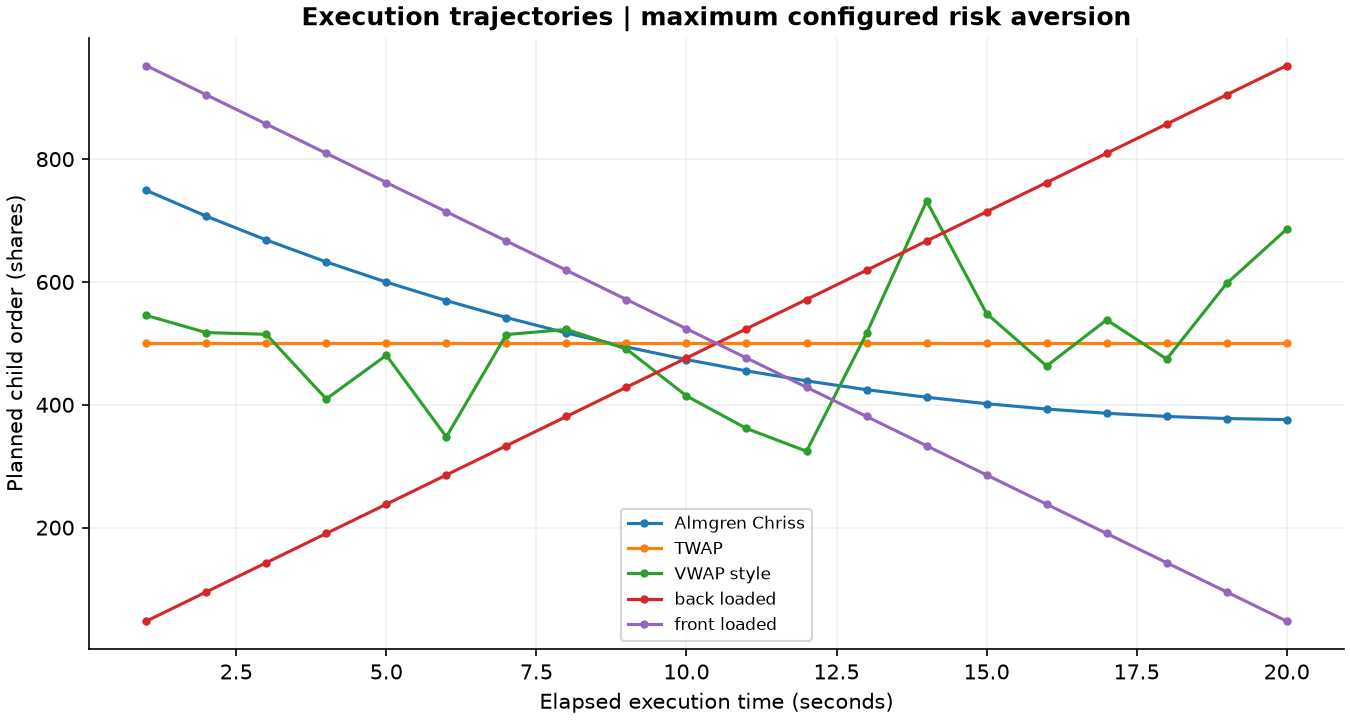

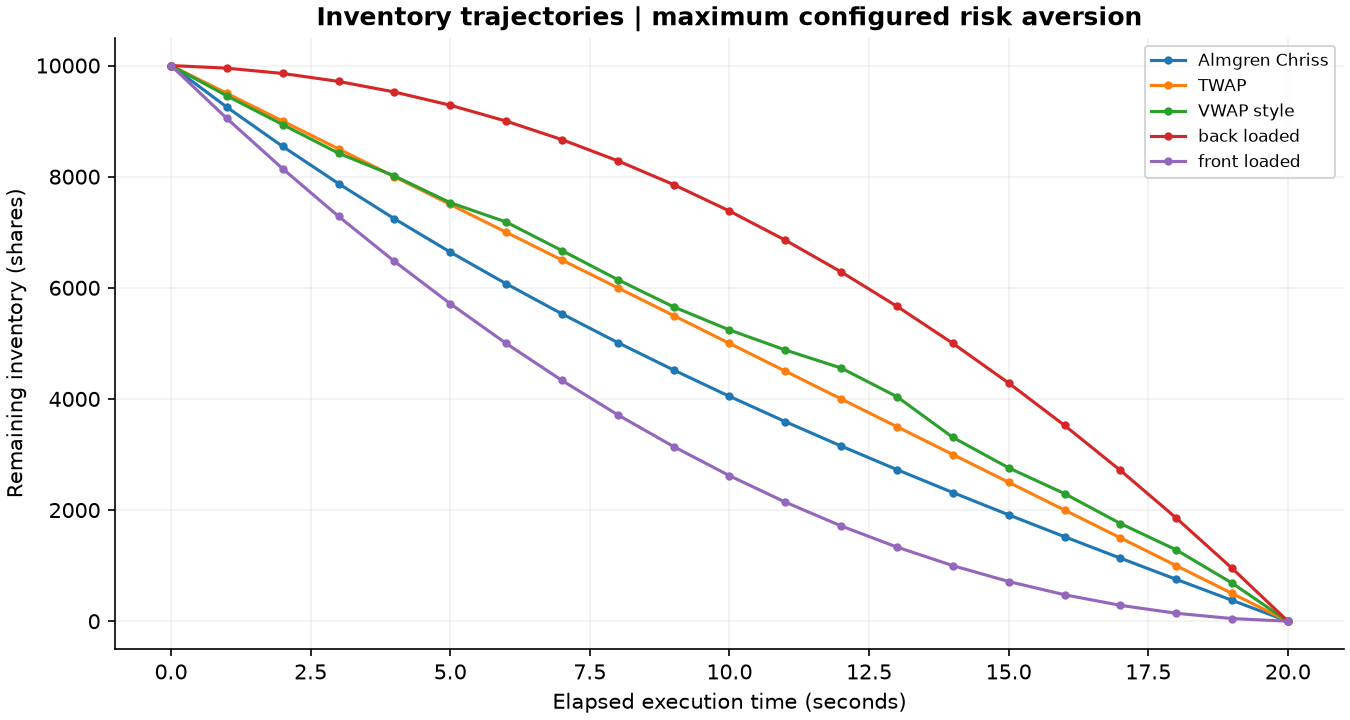

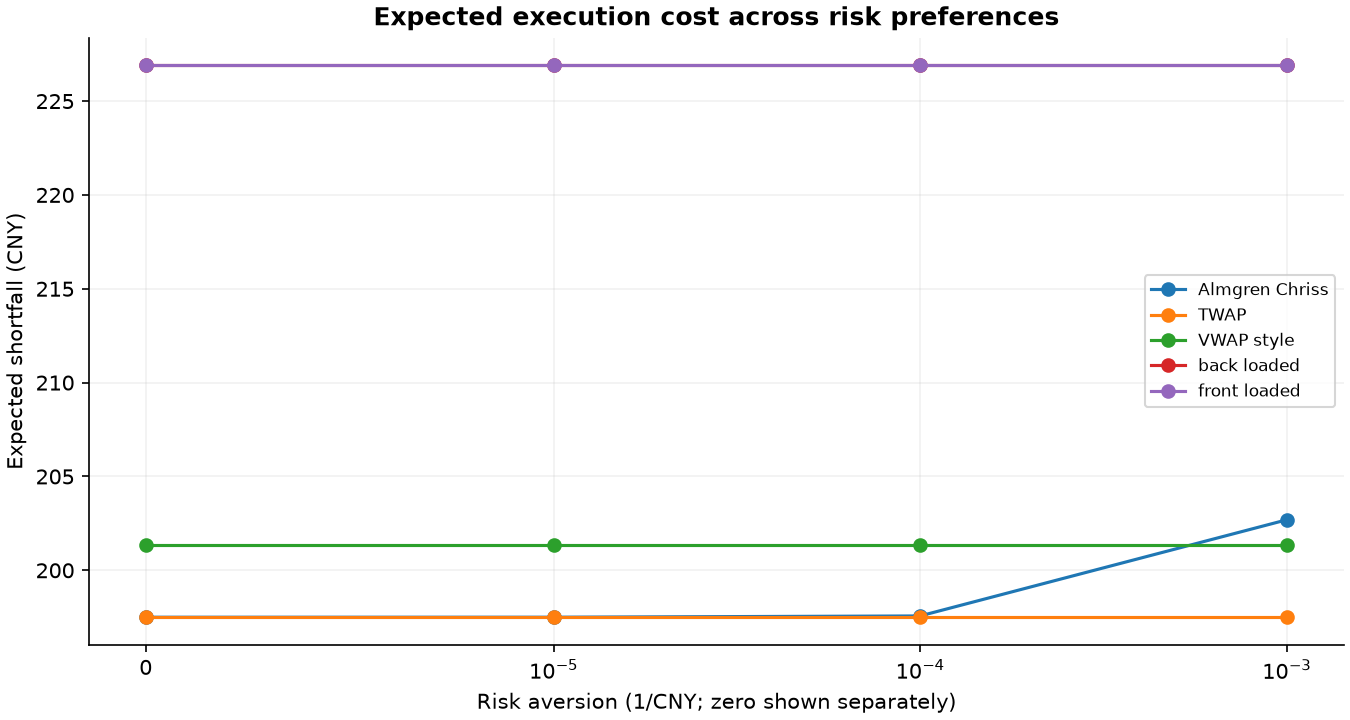

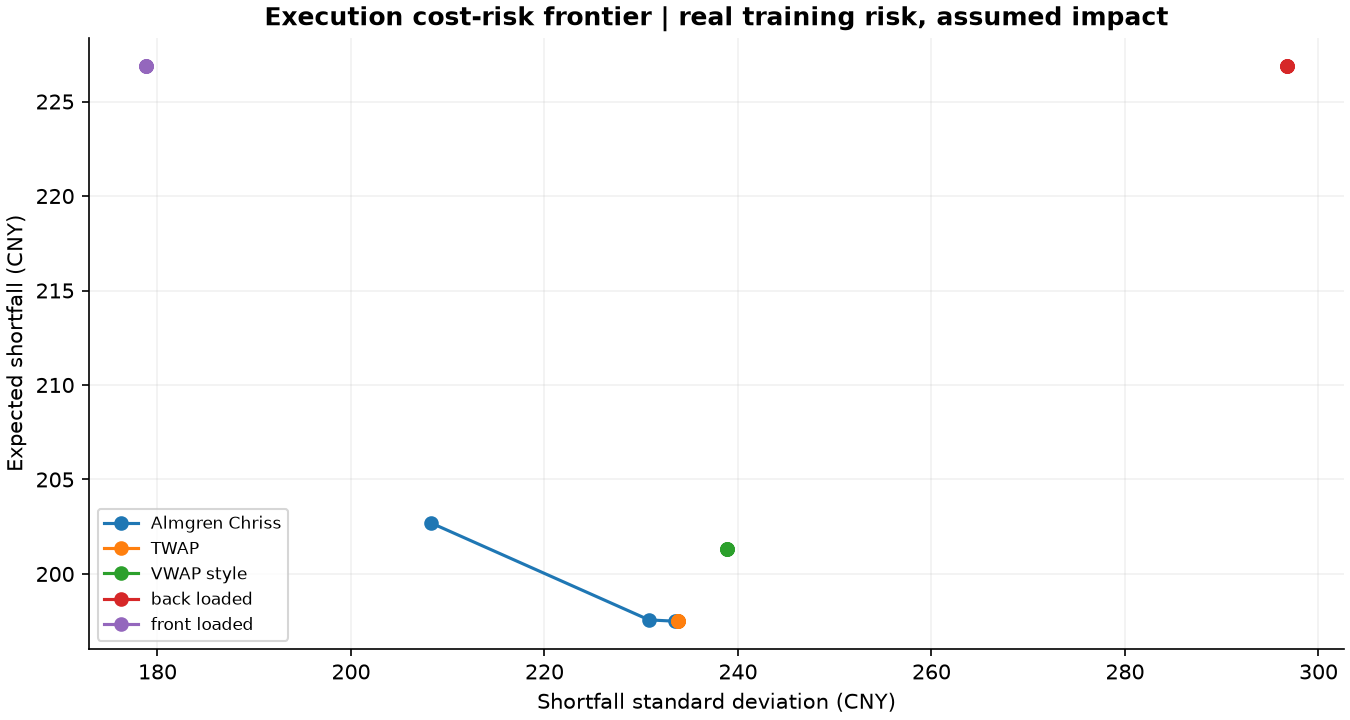

In [3]:
optimal = table('optimal_execution_summary')
assert len(optimal) == 160
base = optimal[(optimal.sigma_multiplier == 1) & (optimal.eta_multiplier == 1) & (optimal.size_multiplier == 1)]
display(base[['schedule','risk_aversion_per_cny','expected_cost_cny','cost_variance_cny2','rounded_expected_cost_cny']])
figure('almgren_chriss_execution_trajectory')
figure('almgren_chriss_inventory_trajectory')
figure('execution_cost_vs_risk_aversion')
figure('execution_cost_risk_frontier')

In [4]:
manifest = json.loads((ROOT / 'outputs/tables/reproducibility_manifest.json').read_text())
assert manifest['synthetic_primary_results'] is False
assert manifest['oos_rows_all_models'] == 31500
assert all((ROOT / 'outputs' / file).is_file() for file in manifest['figures'])
display(pd.Series(manifest['package_versions'], name='locked package versions'))
print(f"Verified {manifest['figure_count']} figure files and real-data provenance.")

numpy             2.4.6
pandas            2.3.3
scipy            1.18.1
scikit-learn      1.9.1
statsmodels      0.14.6
matplotlib       3.11.2
pyarrow          23.0.1
akshare          1.19.1
easyquotation     0.7.7
Name: locked package versions, dtype: object

Verified 33 figure files and real-data provenance.


## Interview conclusion

A statistical signal must be evaluated through an executable account mandate. Here T+1, passive directional exposure, minimum commission and uncertain maker fills prevent treating marked gains as realized high-frequency profitability. Next work: official snapshot reconciliation, licensed multi-day holdouts, own-order fill calibration and settled/multi-day inventories.